![Logo Javeriana](https://images.seeklogo.com/logo-png/11/1/pontificia-universidad-javeriana-logo-png_seeklogo-110703.png)

## Nombres: 
- Gabriel Jaramillo Cuberos (Id: 20529022)
- David Vargas (Id: 20485686)
- Juan Felipe Gómez López (Id: 20553416)
- Sara Pulgarín (Id: 20491129)
- Juan Camilo Delgado (Id: 20506996)

### Primera entrega del proyecto

*Materia:* Procesamiento de Datos (1255)

*Tema:* *Tema:* Consultoría Nueva York.

*Descripción:* En este cuaderno se responden las preguntas:
- ¿Qué combinaciones de día de la semana y franja horaria concentran mayor número de colisiones?
- ¿Qué tipos de vehículos aparecen con mayor frecuencia en las colisiones?
- ¿Qué factores contribuyentes son reportados con mayor frecuencia y cómo varían según el tipo de vehículo?
- 
*Nombre del fichero:* 01_Vehiculos_Accidentes.ipynb

# Cuaderno 2 - Accidentes Viales: vehículos involucrados en siniestros

**Primera entrega: Entendimiento del negocio y de los datos**

**Año objetivo: 2018**

El equipo actúa como consultor para elaborar un diagnóstico histórico de la ciudad de **Nueva York**.
El objetivo es describir arrestos, siniestros y condiciones socioeconómicas, preparar indicadores comparables
y documentar limitaciones para una futura priorización. 

Este cuaderno reúne la preparación y exploración de los datos viales
de la primera entrega y los análisis de la entrega final.

Se responden preguntas sobre los tipos de vehículos, los factores
contribuyentes reportados y las combinaciones de día y franja horaria
con mayor número de colisiones registradas durante 2018.

Los CSV, ubicados en la carpeta de datasets del clúster, se leen con una función compartida del archivo *proyecto.py*. Se ejecuta Spark en el cluster del taller, con un máximo de dos núcleos por aplicación (esto se hace para no ocupar todos los recursos del clúster).

In [4]:
# Comprobar kernel

import sys
import pyspark

print("Python:", sys.version)
print("Ejecutable:", sys.executable)
print("PySpark:", pyspark.__version__)

Python: 3.11.13 (main, Jun  1 2026, 00:00:00) [GCC 11.5.0 20240719 (Red Hat 11.5.0-14)]
Ejecutable: /home/estudiante/jupyter_env/bin/python3.11
PySpark: 4.2.0


## 1. Configuración del cluster

La configuración compartida reproduce los recursos y el Python del taller.

In [5]:
import sys

sys.path.insert(0, "/opt/cluster/Proyecto/Entrega_1/cuadernos")

In [6]:
# Se inicia la sesión spark.

from Utils import proyecto as p
from Utils.proyecto import ANIO, DATA_DIR, RESULTADOS
spark = p.iniciar_spark("Entrega1_Vehiculos")
from pyspark.sql import functions as F
from IPython.display import display, Markdown
print("Directorio de entrada:", DATA_DIR) # Imprime el directorio de donde llegan los datos.
print("Directorio de resultados:", RESULTADOS) # Imprime el directorio a donde van los resultados.

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Python: 3.11.13 | PySpark: 4.2.0 | Spark: 4.2.0
Ejecutable: /home/estudiante/jupyter_env/bin/python3.11
Aplicación: app-20261117095435-0100 | Máximo de núcleos: 2
Los recursos físicos del cluster deben documentarse desde la interfaz del master.
Directorio de entrada: /opt/cluster/Proyecto/Entrega_1/datasets
Directorio de resultados: /opt/cluster/Proyecto/Entrega_1/resultados


In [7]:
sc = spark.sparkContext

# Consultar ejecutores activos
infos = sc._jsc.sc().statusTracker().getExecutorInfos()

print("Ejecutores reportados:", len(infos))

for e in infos:
    print("Host:", e.host())
    print("Puerto:", e.port())
    print("Tareas activas:", e.numRunningTasks())

Ejecutores reportados: 1
Host: NBDG59.javeriana.edu.co
Puerto: 33789
Tareas activas: 0


In [8]:
print(spark.sparkContext.uiWebUrl)

http://NBDG59.javeriana.edu.co:4040


## 2. Fuente y unidad para observar

Entrada: **Accidentes_Viales_NY.csv**. Fuente: [Motor Vehicle Collisions — Vehicles](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Vehicles/bm4k-52h4).
Una fila describe un vehículo involucrado en un accidente y no los detalles de una colisión. `UNIQUE_ID` identifica la fila y `COLLISION_ID`
permite contar colisiones distintas. Varias filas pueden pertenecer a una misma colisión.

Este archivo **no contiene `BOROUGH`, personas lesionadas ni fallecidas**. Por lo tanto no se calcula carga territorial,
mortalidad ni tasas de accidentes.

In [9]:
# Se obtienen los datos en crudo del CSV. Usando el JSON de diccionarios, muestra la descripción de cada uno de los atributos.

df_crudo = p.leer_csv(
    spark,
    "Accidentes_Viales_NY.csv",
    [
        "unique_id",
        "collision_id",
        "crash_date",
        "crash_time",
        "vehicle_type",
        "contributing_factor_1",
        "contributing_factor_2"
    ]
)

df_crudo.printSchema()
p.diccionario(df_crudo, "vehiculos")

root
 |-- unique_id: string (nullable = true)
 |-- collision_id: string (nullable = true)
 |-- crash_date: string (nullable = true)
 |-- crash_time: string (nullable = true)
 |-- vehicle_id: string (nullable = true)
 |-- state_registration: string (nullable = true)
 |-- vehicle_type: string (nullable = true)
 |-- vehicle_make: string (nullable = true)
 |-- vehicle_model: string (nullable = true)
 |-- vehicle_year: string (nullable = true)
 |-- travel_direction: string (nullable = true)
 |-- vehicle_occupants: string (nullable = true)
 |-- driver_sex: string (nullable = true)
 |-- driver_license_status: string (nullable = true)
 |-- driver_license_jurisdiction: string (nullable = true)
 |-- pre_crash: string (nullable = true)
 |-- point_of_impact: string (nullable = true)
 |-- vehicle_damage: string (nullable = true)
 |-- vehicle_damage_1: string (nullable = true)
 |-- vehicle_damage_2: string (nullable = true)
 |-- vehicle_damage_3: string (nullable = true)
 |-- public_property_damage:

atributo,tipo_leido,significado,codigos_notas
unique_id,string (CSV original),Unique record code generated by system. Primary Key.,
collision_id,string (CSV original),"Crash identification code. Foreign Key, matches unique_id from the Crash table.",
crash_date,string (CSV original),Occurrence date of collision,
crash_time,string (CSV original),Occurrence time of collision,
vehicle_id,string (CSV original),Vehicle identification code assigned by system,
state_registration,string (CSV original),State where vehicle is registered.,
vehicle_type,string (CSV original),"Type of vehicle based on the selected vehicle category (ATV, bicycle, car/suv, ebike, escooter, truck/bus, motorcycle, other)",
vehicle_make,string (CSV original),Vehicle make,
vehicle_model,string (CSV original),Vehicle model,
vehicle_year,string (CSV original),Year the vehicle was manufactured,


## 3. Calidad y cobertura

El reporte de faltantes abarca todas las columnas del archivo. Las tablas se agregan en Spark. El CSV no se modifica.

columna,faltantes,total,porcentaje
unique_id,0,4551002,0.0
collision_id,0,4551002,0.0
crash_date,0,4551002,0.0
crash_time,0,4551002,0.0
vehicle_id,0,4551002,0.0
state_registration,370303,4551002,8.137
vehicle_type,281138,4551002,6.177
vehicle_make,1955257,4551002,42.963
vehicle_model,4490072,4551002,98.661
vehicle_year,1981905,4551002,43.549


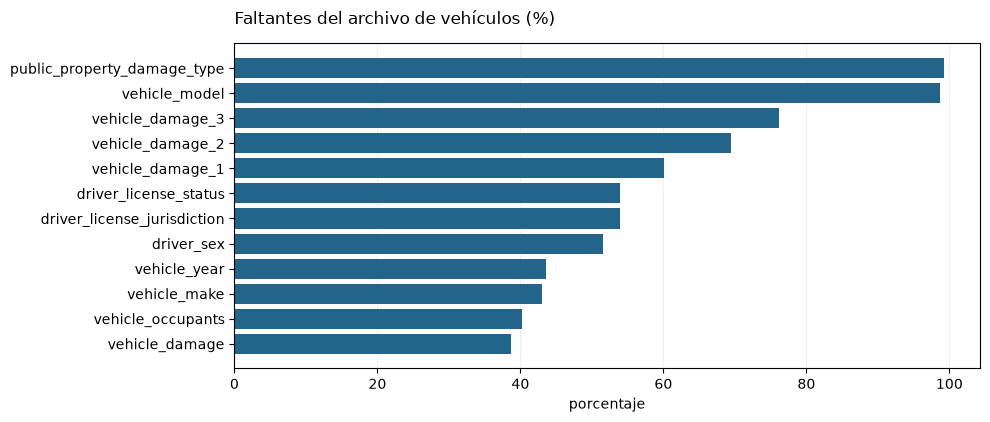

anio,count
2012,198968
2013,404702
2014,409087
2015,434607
2016,457944
2017,464544
2018,465822
2019,426724
2020,231211
2021,227267


In [10]:
reporte = p.calidad(df_crudo)
p.tabla(reporte, 100)
p.guardar_json("02_calidad_vehiculos.json", reporte)
p.barras(sorted(
    reporte, 
    key=lambda r:r["faltantes"], 
    reverse=True
)[:12], 
         "columna", 
         "porcentaje",
         "Faltantes del archivo de vehículos (%)", 
         "calidad_vehiculos.png"
        )

base = df_crudo.withColumn("fecha", p.fecha("crash_date"))
anios = p.cobertura(base)
p.tabla(anios)
p.guardar_json("cobertura_vehiculos.json", anios)
periodo = base.filter(F.year("fecha") == ANIO)

## 4. Duplicados, claves y transformaciones iniciales

Se aplican los mismos filtros usados en el cuaderno de arrestos para eliminar filas con conflictos. Se usa `UNIQUE_ID` para duplicados, nunca `COLLISION_ID` ya que eliminar duplicados por colisión borraría vehículos válidos. Las categorías desconocidas permanecen de esa forma. No se tienen en cuenta año del vehículo, sexo o factores.

In [11]:
limpio, auditoria = p.depurar_identificador(periodo, ["unique_id"])
limpio = (limpio.withColumn(
    "tipo_vehiculo", 
    F.coalesce(
        F.upper(
            p.texto("vehicle_type")
        ), 
        F.lit("SIN DATO")
    )
)
          
    .withColumn(
        "factor_reportado", 
        F.coalesce(
            p.texto("contributing_factor_1"), 
            F.lit("SIN DATO")
        )
    )
          
    .withColumn("anio", F.year("fecha"))
         )

auditoria["sin_collision_id"] = limpio.filter(p.texto("collision_id").isNull()).count()

p.tabla([auditoria])

ruta = p.guardar_json("02_limpieza_vehiculos.json", auditoria)
print("Reporte guardado en:", ruta)

26/11/17 09:55:46 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

filas_originales,duplicados_exactos,filas_sin_clave,filas_con_clave_conflictiva_excluidas,filas_conservadas,sin_collision_id
465822,0,0,0,465822,0


Reporte guardado en: /opt/cluster/Proyecto/Entrega_1/resultados/02_limpieza_vehiculos.json


## 5. Filas y colisiones identificables

Los aquí contados son las colisiones representadas en la tabla de vehículos. Se cuentan vehículos y colisiones por separado.

In [12]:
totales = limpio.agg(F.count("*").alias("filas_vehiculos"), # Cuenta todas las filas conservadas
    F.countDistinct(p.texto("collision_id")).alias("colisiones_identificables")) # Cuenta identificadores de colisión diferentes

p.tabla(p.filas(totales))
ruta = p.guardar_json("unidades_vehiculos.json", p.filas(totales))
print("Reporte guardado en:", ruta)

filas_vehiculos,colisiones_identificables
465822,231542


Reporte guardado en: /opt/cluster/Proyecto/Entrega_1/resultados/unidades_vehiculos.json


## 6. Vehículos por colisión registrada

La distribución se agrupa hasta cinco vehículos y una categoría de seis o más. No mide la severidad de los accidentes.

vehiculos_por_colision,count
1,18631
2,196499
3,12936
4,2558
5,618
6 o más,300


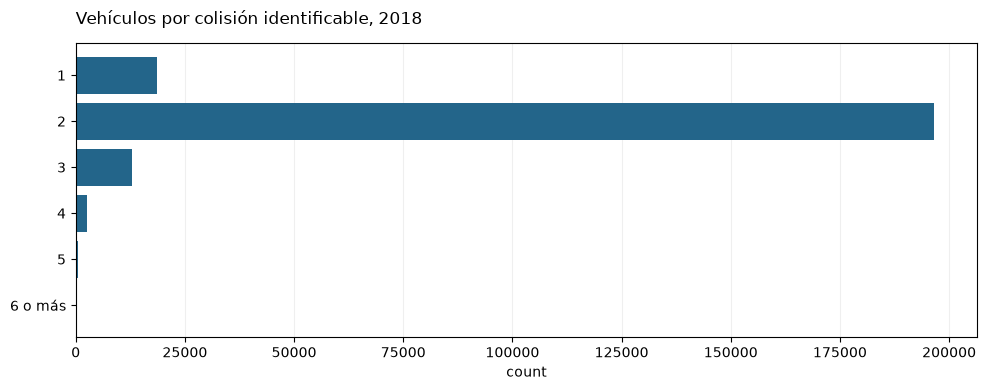

In [13]:
# Se seleccionan las filas con el identificador de colisión. Luego se agrupa las que tienen la misma colisión y se cuenta el registro

por_colision = limpio.filter(p.texto("collision_id").isNotNull()).groupBy("collision_id").count()
distribucion = (por_colision.withColumn("vehiculos_por_colision", F.when(F.col("count") >= 6, "6 o más")
    .otherwise(F.col("count").cast("string"))).groupBy("vehiculos_por_colision").count().orderBy("vehiculos_por_colision"))
datos = p.filas(distribucion)
p.tabla(datos)
p.barras(datos, "vehiculos_por_colision", "count", "Vehículos por colisión identificable, 2018", "vehiculos_por_colision.png")

Se define una función para pintar el mapa de calor.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

from pyspark.sql import Window

#Mostrar y guardar un mapa de calor. Recibe únicamente una tabla pequeña ya agregada.
def mostrar_mapa(matriz, titulo, archivo, unidad, decimales=0):
    if matriz.empty:
        print("No hay datos para:", titulo)
        return

    valores = matriz.to_numpy(dtype=float)

    fig, ax = plt.subplots(
        figsize=(14, max(4, len(matriz) * 0.65))
    )

    imagen = ax.imshow(
        valores,
        cmap="Blues",
        aspect="auto"
    )

    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(
        [
            textwrap.fill(str(columna), 24)
            for columna in matriz.columns
        ],
        rotation=35,
        ha="right",
        fontsize=9
    )

    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index, fontsize=9)

    # Escribir el valor de cada celda.
    for i in range(len(matriz.index)):
        for j in range(len(matriz.columns)):
            ax.text(
                j,
                i,
                f"{valores[i, j]:.{decimales}f}",
                ha="center",
                va="center",
                fontsize=8,
                color=(
                    "white"
                    if valores[i, j] > valores.max() / 2
                    else "black"
                )
            )

    ax.set_title(titulo)
    fig.colorbar(imagen, ax=ax, label=unidad)
    fig.tight_layout()

    fig.savefig(
        RESULTADOS / archivo,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

## 7. Tipos de vehículo

Esta sección responde qué tipos de vehículos aparecen con mayor frecuencia
en los registros de colisiones de 2018.

Se distingue entre cantidad de registros de vehículos y cantidad de
colisiones identificables donde aparece cada tipo. Los porcentajes se
calculan sobre todos los registros de vehículos conservados.

Una mayor frecuencia no demuestra mayor riesgo por viaje, porque no
disponemos de una medida de circulación o exposición de cada tipo.

tipo_vehiculo,count,colisiones_con_tipo,porcentaje_vehiculos
SEDAN,197097,149622,42.31
STATION WAGON/SPORT UTILITY VEHICLE,154928,122103,33.26
SIN DATO,33151,32579,7.12
TAXI,21798,19213,4.68
PICK-UP TRUCK,14232,13676,3.06
BOX TRUCK,10011,9711,2.15
BUS,7173,6975,1.54
BIKE,6238,6148,1.34
TRACTOR TRUCK DIESEL,3791,3672,0.81
VAN,3261,3156,0.7


Resumen guardado en: /opt/cluster/Proyecto/Entrega_1/resultados/tipos_vehiculo.json


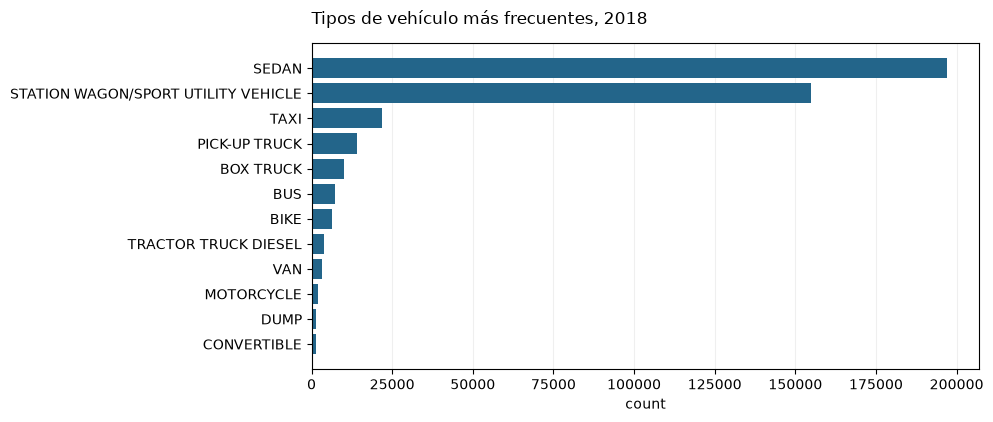

In [15]:
# Recuperar los totales que ya calculamos en la sección 5.
datos_totales = p.filas(totales)[0]

total_vehiculos = datos_totales["filas_vehiculos"]
total_colisiones = datos_totales["colisiones_identificables"]

if total_vehiculos == 0:
    raise ValueError(
        "No hay vehículos para analizar. "
        "Revisa la cobertura y la limpieza."
    )

# Ampliar el resumen existente por tipo.
tipos_resumen = (
    limpio
    .groupBy("tipo_vehiculo")
    .agg(
        # Registros de vehículos de cada tipo.
        F.count("*").alias("count"),

        # Colisiones diferentes donde aparece el tipo.
        F.countDistinct(
            p.texto("collision_id")
        ).alias("colisiones_con_tipo")
    )
    .withColumn(
        "porcentaje_vehiculos",
        F.round(
            100.0 * F.col("count") / total_vehiculos,
            2
        )
    )
    .orderBy(
        F.desc("count"),
        "tipo_vehiculo"
    )
)

# Mantener el resumen de doce etiquetas que ya tenía el cuaderno.
tipos = p.filas(
    tipos_resumen.limit(12)
)

p.tabla(tipos)

ruta = p.guardar_json(
    "tipos_vehiculo.json",
    tipos
)

print("Resumen guardado en:", ruta)

# Para la gráfica seleccionamos tipos conocidos.
# SIN DATO sigue presente en el resumen y en su denominador.
tipos_conocidos = p.filas(
    tipos_resumen
    .filter(
        F.col("tipo_vehiculo") != "SIN DATO"
    )
    .limit(12)
)

p.barras(
    tipos_conocidos,
    "tipo_vehiculo",
    "count",
    f"Tipos de vehículo más frecuentes, {ANIO}",
    "tipos_vehiculo.png"
)

## 8. Factores contribuyentes

Esta sección responde cuáles son los factores específicos más frecuentes
y cómo varían entre tipos de vehículos.

Se utilizan ambos campos de factores contribuyentes. Un mismo factor
repetido en los dos campos del mismo vehículo se cuenta una sola vez.

Los factores ausentes y no especificados se presentan como una
limitación de información. Los resultados describen factores reportados,
sin demostrar por sí solos causalidad o responsabilidad.

estado_factor,count,porcentaje
Ausente,19186,4.12
Informado,219526,47.13
No especificado,227110,48.75


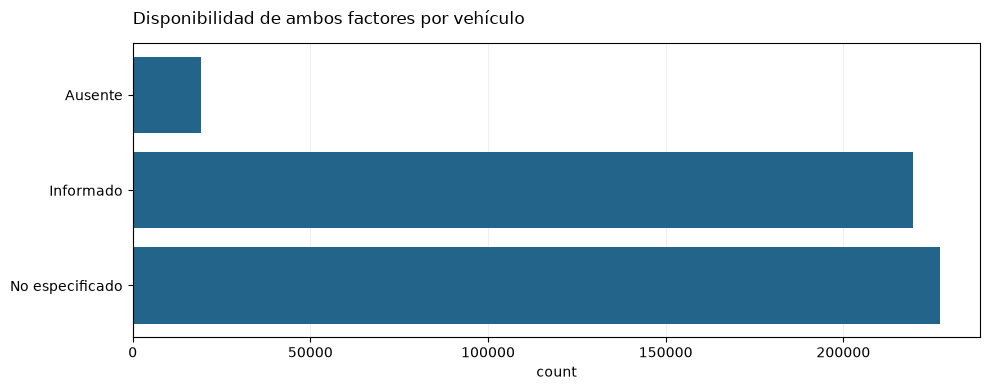

In [16]:
# Seleccionar columnas del DataFrame ya depurado.
factores_base = limpio.select(
    "unique_id",
    "tipo_vehiculo",
    "contributing_factor_1",
    "contributing_factor_2"
)

# Aplicar la misma normalización a ambos campos:
# espacios, mayúsculas y valores vacíos.
for original, nueva in [
    ("contributing_factor_1", "factor_1"),
    ("contributing_factor_2", "factor_2")
]:
    valor = F.upper(
        F.trim(
            F.regexp_replace(
                p.texto(original),
                r"\s+",
                " "
            )
        )
    )

    factores_base = factores_base.withColumn(
        nueva,
        F.when(
            F.length(valor) > 0,
            valor
        )
    )

# Un factor específico tiene contenido y no es UNSPECIFIED.
especifico_1 = (
    F.col("factor_1").isNotNull()
    & (F.col("factor_1") != "UNSPECIFIED")
)

especifico_2 = (
    F.col("factor_2").isNotNull()
    & (F.col("factor_2") != "UNSPECIFIED")
)

# Clasificar cada vehículo una sola vez.
factores_base = factores_base.withColumn(
    "estado_factor",

    F.when(
        especifico_1 | especifico_2,
        "Informado"
    )

    .when(
        (F.col("factor_1") == "UNSPECIFIED")
        | (F.col("factor_2") == "UNSPECIFIED"),
        "No especificado"
    )

    .otherwise("Ausente")
)

disponibilidad_factores = (
    factores_base
    .groupBy("estado_factor")
    .count()
    .withColumn(
        "porcentaje",
        F.round(
            100.0 * F.col("count") / total_vehiculos,
            2
        )
    )
)

datos_disponibilidad = p.filas(
    disponibilidad_factores
)

p.tabla(datos_disponibilidad)

p.guardar_json(
    "E2_disponibilidad_factores.json",
    datos_disponibilidad
)

p.barras(
    datos_disponibilidad,
    "estado_factor",
    "count",
    "Disponibilidad de ambos factores por vehículo",
    "E2_disponibilidad_factores.png"
)

factor,vehiculos_con_factor,porcentaje_total_vehiculos
DRIVER INATTENTION/DISTRACTION,88441,18.99
FOLLOWING TOO CLOSELY,35765,7.68
FAILURE TO YIELD RIGHT-OF-WAY,24726,5.31
PASSING OR LANE USAGE IMPROPER,18406,3.95
PASSING TOO CLOSELY,15716,3.37
UNSAFE LANE CHANGING,14563,3.13
BACKING UNSAFELY,13918,2.99
OTHER VEHICULAR,11962,2.57
TURNING IMPROPERLY,9527,2.05
DRIVER INEXPERIENCE,8752,1.88


Se muestran 20 de 54 filas; la salida guardada contiene todas.


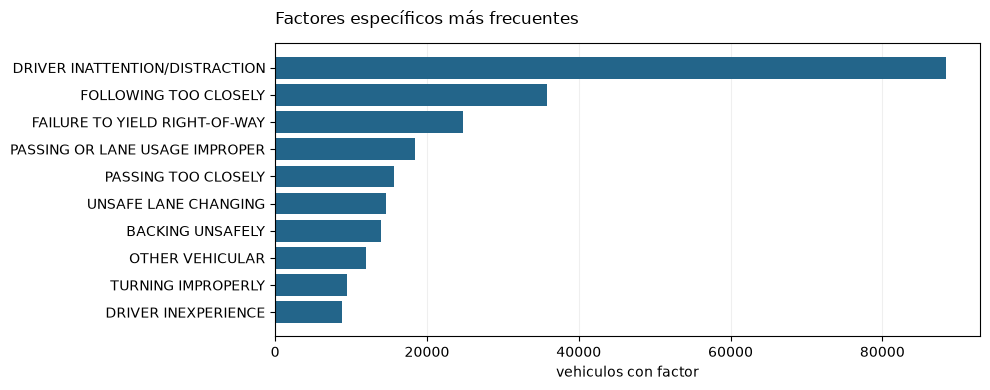

In [17]:
# Convertir los dos campos de factores en filas.
factores_detalle = (
    factores_base
    .select(
        "unique_id",
        "tipo_vehiculo",

        F.explode(
            F.array(
                "factor_1",
                "factor_2"
            )
        ).alias("factor")
    )

    # Conservar únicamente factores específicos.
    .filter(
        F.col("factor").isNotNull()
        & (F.col("factor") != "UNSPECIFIED")
    )

    # Si un vehículo repite el mismo factor en ambos campos,
    # ese factor aporta una sola vez.
    .dropDuplicates(
        ["unique_id", "factor"]
    )
)

ranking_factores = (
    factores_detalle
    .groupBy("factor")
    .agg(
        F.count("*").alias("vehiculos_con_factor")
    )
    .withColumn(
        "porcentaje_total_vehiculos",
        F.round(
            100.0
            * F.col("vehiculos_con_factor")
            / total_vehiculos,
            2
        )
    )
    .orderBy(
        F.desc("vehiculos_con_factor"),
        "factor"
    )
)

datos_factores = p.filas(
    ranking_factores
)

p.tabla(
    datos_factores,
    limite=20
)

p.guardar_json(
    "E2_ranking_factores.json",
    datos_factores
)

p.barras(
    datos_factores[:10],
    "factor",
    "vehiculos_con_factor",
    "Factores específicos más frecuentes",
    "E2_ranking_factores.png"
)

In [18]:
# Contar vehículos diferentes que tienen algún factor específico.
# countDistinct evita contar dos veces al vehículo con dos factores.
informados_por_tipo = (
    factores_detalle
    .groupBy("tipo_vehiculo")
    .agg(
        F.countDistinct("unique_id")
        .alias("vehiculos_con_factor_informado")
    )
)

# Reutilizar los totales por tipo calculados en la sección 7.
cobertura_por_tipo = (
    tipos_resumen
    .select(
        "tipo_vehiculo",
        F.col("count").alias("total_vehiculos_tipo")
    )
    .join(
        informados_por_tipo,
        "tipo_vehiculo",
        "left"
    )
    .fillna({
        "vehiculos_con_factor_informado": 0
    })
    .withColumn(
        "cobertura_factor_pct",
        F.round(
            100.0
            * F.col("vehiculos_con_factor_informado")
            / F.col("total_vehiculos_tipo"),
            2
        )
    )
)

# Contar cada combinación de tipo y factor.
comparacion_factores = (
    factores_detalle
    .groupBy(
        "tipo_vehiculo",
        "factor"
    )
    .agg(
        F.count("*").alias("vehiculos_con_factor")
    )
    .join(
        cobertura_por_tipo,
        "tipo_vehiculo"
    )
    .withColumn(
        "porcentaje_del_tipo",
        F.round(
            100.0
            * F.col("vehiculos_con_factor")
            / F.col("total_vehiculos_tipo"),
            2
        )
    )
)

comparacion_factores.orderBy(
    F.desc("vehiculos_con_factor")
).select(
    "tipo_vehiculo",
    "factor",
    "vehiculos_con_factor",
    "total_vehiculos_tipo",
    "porcentaje_del_tipo",
    "cobertura_factor_pct"
).show(20, truncate=False)

# Guardar el cruce completo con Spark.
# Puede superar el límite de tablas pequeñas de p.filas.
ruta_comparacion = (
    RESULTADOS / "E2_factores_por_tipo_csv"
).as_uri()

(
    comparacion_factores.write
    .mode("overwrite")
    .option("header", True)
    .csv(ruta_comparacion)
)

print("Comparación completa guardada en:", ruta_comparacion)

# Ordenar los factores dentro de cada tipo de vehículo.
ventana_factores = (
    Window
    .partitionBy("tipo_vehiculo")
    .orderBy(
        F.desc("vehiculos_con_factor")
    )
)

# Mantener todos los factores empatados en el primer puesto.
lideres_factores = (
    comparacion_factores
    .withColumn(
        "puesto",
        F.dense_rank().over(ventana_factores)
    )
    .filter(
        F.col("puesto") == 1
    )
    .drop("puesto")
)

print("Factores más frecuentes dentro de cada tipo:")

p.tabla(
    p.filas(
        lideres_factores
        .orderBy(
            F.desc("total_vehiculos_tipo")
        )
        .select(
            "tipo_vehiculo",
            "factor",
            "vehiculos_con_factor",
            "porcentaje_del_tipo",
            "cobertura_factor_pct"
        )
        .limit(20)
    )
)

(
    lideres_factores.write
    .mode("overwrite")
    .option("header", True)
    .csv(
        (
            RESULTADOS
            / "E2_factores_lideres_por_tipo_csv"
        ).as_uri()
    )
)

+-----------------------------------+------------------------------+--------------------+--------------------+-------------------+--------------------+
|tipo_vehiculo                      |factor                        |vehiculos_con_factor|total_vehiculos_tipo|porcentaje_del_tipo|cobertura_factor_pct|
+-----------------------------------+------------------------------+--------------------+--------------------+-------------------+--------------------+
|SEDAN                              |DRIVER INATTENTION/DISTRACTION|36374               |197097              |18.45              |45.69               |
|STATION WAGON/SPORT UTILITY VEHICLE|DRIVER INATTENTION/DISTRACTION|29541               |154928              |19.07              |46.65               |
|SEDAN                              |FOLLOWING TOO CLOSELY         |15855               |197097              |8.04               |45.69               |
|STATION WAGON/SPORT UTILITY VEHICLE|FOLLOWING TOO CLOSELY         |12792               

Comparación completa guardada en: file:///opt/cluster/Proyecto/Entrega_1/resultados/E2_factores_por_tipo_csv
Factores más frecuentes dentro de cada tipo:


tipo_vehiculo,factor,vehiculos_con_factor,porcentaje_del_tipo,cobertura_factor_pct
SEDAN,DRIVER INATTENTION/DISTRACTION,36374,18.45,45.69
STATION WAGON/SPORT UTILITY VEHICLE,DRIVER INATTENTION/DISTRACTION,29541,19.07,46.65
SIN DATO,DRIVER INATTENTION/DISTRACTION,5332,16.08,36.46
TAXI,DRIVER INATTENTION/DISTRACTION,5408,24.81,55.72
PICK-UP TRUCK,DRIVER INATTENTION/DISTRACTION,2993,21.03,53.65
BOX TRUCK,DRIVER INATTENTION/DISTRACTION,2404,24.01,66.07
BUS,DRIVER INATTENTION/DISTRACTION,1310,18.26,51.74
BIKE,DRIVER INATTENTION/DISTRACTION,1188,19.04,55.1
TRACTOR TRUCK DIESEL,DRIVER INATTENTION/DISTRACTION,729,19.23,57.21
VAN,DRIVER INATTENTION/DISTRACTION,670,20.55,57.59


Cobertura de los tipos incluidos en el mapa:


+-----------------------------------+--------------------+------------------------------+--------------------+
|tipo_vehiculo                      |total_vehiculos_tipo|vehiculos_con_factor_informado|cobertura_factor_pct|
+-----------------------------------+--------------------+------------------------------+--------------------+
|SEDAN                              |197097              |90056                         |45.69               |
|STATION WAGON/SPORT UTILITY VEHICLE|154928              |72268                         |46.65               |
|TAXI                               |21798               |12145                         |55.72               |
|PICK-UP TRUCK                      |14232               |7635                          |53.65               |
|BOX TRUCK                          |10011               |6614                          |66.07               |
|BUS                                |7173                |3711                          |51.74               |
|

/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

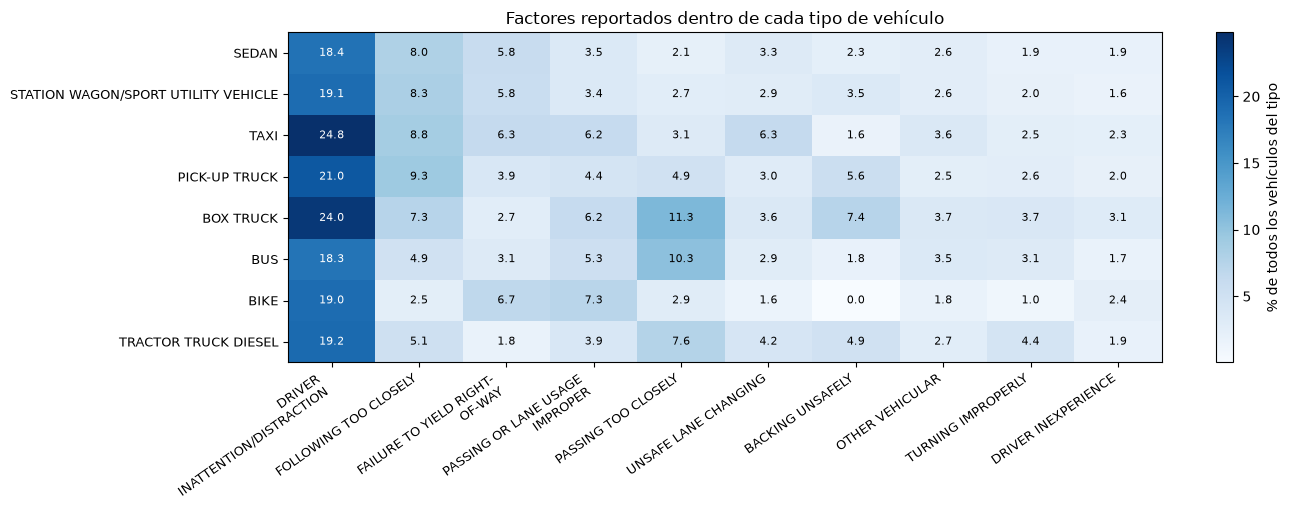

In [19]:
# Seleccionar grupos frecuentes para mantener legible la gráfica.
# La comparación completa ya quedó guardada.
tipos_mapa = [
    fila["tipo_vehiculo"]
    for fila in tipos_conocidos[:8]
]

factores_mapa = [
    fila["factor"]
    for fila in datos_factores[:10]
]

if tipos_mapa and factores_mapa:

    print("Cobertura de los tipos incluidos en el mapa:")

    (
        cobertura_por_tipo
        .filter(
            F.col("tipo_vehiculo").isin(tipos_mapa)
        )
        .orderBy(
            F.desc("total_vehiculos_tipo")
        )
        .show(truncate=False)
    )

    # Pasar a pandas únicamente el cruce pequeño para dibujarlo.
    pequena = (
        comparacion_factores
        .filter(
            F.col("tipo_vehiculo").isin(tipos_mapa)
            & F.col("factor").isin(factores_mapa)
        )
        .select(
            "tipo_vehiculo",
            "factor",
            "porcentaje_del_tipo"
        )
        .toPandas()
    )

    matriz_factores = (
        pequena
        .pivot(
            index="tipo_vehiculo",
            columns="factor",
            values="porcentaje_del_tipo"
        )
        .reindex(
            index=tipos_mapa,
            columns=factores_mapa
        )
        .fillna(0)
    )

    mostrar_mapa(
        matriz_factores,
        "Factores reportados dentro de cada tipo de vehículo",
        "E2_factores_por_tipo.png",
        "% de todos los vehículos del tipo",
        decimales=1
    )

else:
    print(
        "No hay tipos conocidos o factores específicos "
        "suficientes para el mapa."
    )

## 9. Generar resumen

Se guarda un resumen global con `anio` con el objetivo de que el cuaderno de integración pueda leerlo.

In [20]:
resumen = limpio.groupBy("anio").agg(
    F.count("*").alias("filas_vehiculos"),
    
    F.countDistinct(
        p.texto("collision_id")
    ).alias("colisiones_identificables")
)

p.exportar_resumen(
    resumen, 
    "vehiculos_resumen.json", 
    "Accidentes_Viales_NY.csv", 
    "sin_geografia_ni_victimas",
    {
        "auditoria": auditoria, 
        "cobertura": anios, 
        "columnas_ausentes": [
            "borough", 
            "personas_lesionadas", 
            "personas_fallecidas"
        ]
    }
)

print("Resumen global guardado.")

[Stage 233:============================>                            (4 + 2) / 8]

Resumen global guardado.


## 10. Día de la semana y franja horaria

Esta sección responde qué combinaciones de día de la semana y franja
horaria concentran mayor número de colisiones registradas.

Se construye una fila por colisión con fecha y hora consistentes.
Las colisiones sin hora válida o con información temporal contradictoria
se excluyen únicamente de este análisis.

Se utilizan seis franjas de cuatro horas para comparar períodos
de igual duración.

In [21]:
# Reutilizar fecha y columnas originales de limpio.
horarios_base = (
    limpio
    .select(
        p.texto("collision_id").alias("id_colision"),
        "fecha",
        p.texto("crash_time").alias("hora_original")
    )
    .filter(
        F.col("id_colision").isNotNull()
    )
)

# Formatos admitidos: 9:05, 09:05 y 09:05:30.
# Se valida que la hora esté entre 0 y 23 y los minutos entre 0 y 59.
patron_hora = r"^([01]?\d|2[0-3]):([0-5]\d)(?::[0-5]\d)?$"

# Convertir a minutos desde medianoche.
# Si el texto no coincide, try_cast devuelve nulo.
horarios_base = horarios_base.withColumn(
    "minuto_dia",

    60 * F.regexp_extract(
        "hora_original",
        patron_hora,
        1
    ).try_cast("int")

    + F.regexp_extract(
        "hora_original",
        patron_hora,
        2
    ).try_cast("int")
)

# Revisar si los vehículos de una misma colisión
# coinciden en su información temporal.
control_horarios = (
    horarios_base
    .groupBy("id_colision")
    .agg(
        F.countDistinct("fecha")
        .alias("n_fechas"),

        F.countDistinct("minuto_dia")
        .alias("n_horas"),

        # Contar únicamente pares completos de fecha y hora.
        F.countDistinct(
            F.when(
                F.col("minuto_dia").isNotNull(),
                F.struct("fecha", "minuto_dia")
            )
        ).alias("n_pares")
    )
)

ids_horarios_validos = (
    control_horarios
    .filter(
        (F.col("n_fechas") == 1)
        & (F.col("n_horas") == 1)
        & (F.col("n_pares") == 1)
    )
    .select("id_colision")
)

# Crear una fila temporal por colisión.
colisiones_horarios = (
    horarios_base
    .join(
        ids_horarios_validos,
        "id_colision",
        "left_semi"
    )
    .filter(
        F.col("minuto_dia").isNotNull()
    )
    .select(
        "id_colision",
        "fecha",
        "minuto_dia"
    )

    # Aquí se eliminan representaciones temporales idénticas,
    # no vehículos de limpio.
    .distinct()

    # Convertir a lunes=1 ... domingo=7.
    .withColumn(
        "dia_num",
        ((F.dayofweek("fecha") + 5) % 7) + 1
    )

    # Cada franja tiene 240 minutos.
    .withColumn(
        "franja_num",
        F.floor(
            F.col("minuto_dia") / 240
        ).cast("int")
    )
)

n_colisiones_horarios = colisiones_horarios.count()

auditoria_horarios = {
    "colisiones_identificables": total_colisiones,

    "colisiones_horario_valido": n_colisiones_horarios,

    "colisiones_fuera_analisis_temporal": (
        total_colisiones - n_colisiones_horarios
    ),

    "filas_sin_collision_id": auditoria["sin_collision_id"],

    "colisiones_sin_hora_valida": (
        control_horarios
        .filter(F.col("n_horas") == 0)
        .count()
    ),

    "colisiones_con_conflicto_temporal": (
        control_horarios
        .filter(
            (F.col("n_fechas") > 1)
            | (F.col("n_horas") > 1)
        )
        .count()
    )
}

p.tabla([
    {"control": clave, "valor": valor}
    for clave, valor in auditoria_horarios.items()
])

p.guardar_json(
    "E2_auditoria_horarios.json",
    auditoria_horarios
)

if n_colisiones_horarios == 0:
    raise ValueError(
        "No hay colisiones con fecha y hora válidas. "
        "Revisa los valores de crash_time."
    )

control,valor
colisiones_identificables,231542
colisiones_horario_valido,231542
colisiones_fuera_analisis_temporal,0
filas_sin_collision_id,0
colisiones_sin_hora_valida,0
colisiones_con_conflicto_temporal,0


dia_num,franja_num,dia,franja,colisiones,porcentaje
1,0,Lunes,00:00–03:59,2048,0.88
1,1,Lunes,04:00–07:59,2912,1.26
1,2,Lunes,08:00–11:59,8002,3.46
1,3,Lunes,12:00–15:59,8138,3.51
1,4,Lunes,16:00–19:59,8686,3.75
1,5,Lunes,20:00–23:59,3805,1.64
2,0,Martes,00:00–03:59,1519,0.66
2,1,Martes,04:00–07:59,2843,1.23
2,2,Martes,08:00–11:59,8545,3.69
2,3,Martes,12:00–15:59,8680,3.75


Combinaciones con el mayor número de colisiones registradas:


dia_num,franja_num,dia,franja,colisiones,porcentaje
5,4,Viernes,16:00–19:59,9863,4.26


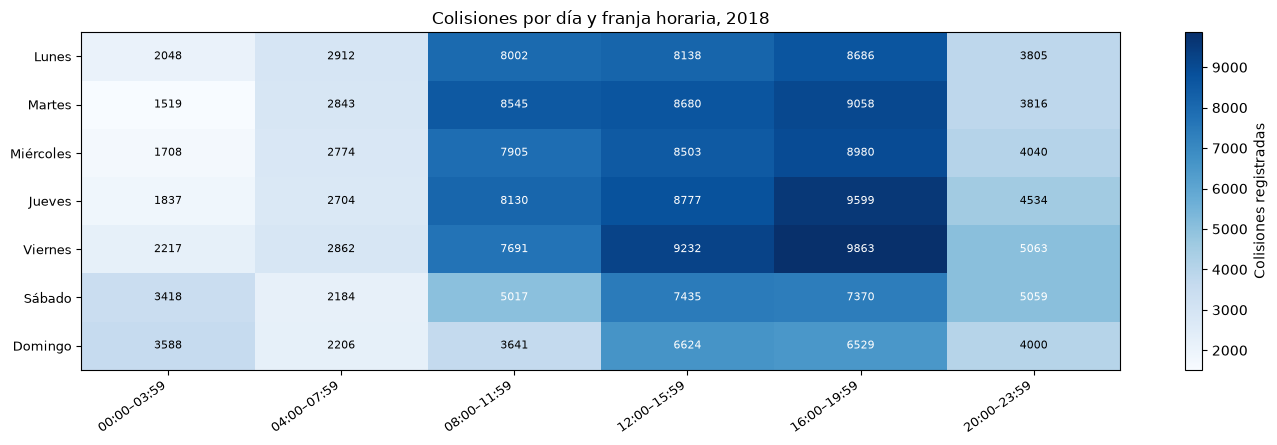

In [22]:
DIAS = [
    "Lunes",
    "Martes",
    "Miércoles",
    "Jueves",
    "Viernes",
    "Sábado",
    "Domingo"
]

FRANJAS = [
    "00:00–03:59",
    "04:00–07:59",
    "08:00–11:59",
    "12:00–15:59",
    "16:00–19:59",
    "20:00–23:59"
]

# Crear las 42 combinaciones posibles.
catalogo_horarios = spark.createDataFrame(
    [
        (i + 1, dia, j, franja)
        for i, dia in enumerate(DIAS)
        for j, franja in enumerate(FRANJAS)
    ],
    """
    dia_num int,
    dia string,
    franja_num int,
    franja string
    """
)

# Cada fila de colisiones_horarios representa una colisión.
conteos_horarios = (
    colisiones_horarios
    .groupBy(
        "dia_num",
        "franja_num"
    )
    .agg(
        F.count("*").alias("colisiones")
    )
)

tabla_horarios = (
    catalogo_horarios
    .join(
        conteos_horarios,
        ["dia_num", "franja_num"],
        "left"
    )

    # Cero significa que no hay eventos válidos registrados
    # en esa combinación dentro del archivo analizado.
    .fillna({"colisiones": 0})

    .withColumn(
        "porcentaje",
        F.round(
            100.0
            * F.col("colisiones")
            / n_colisiones_horarios,
            2
        )
    )

    .orderBy(
        "dia_num",
        "franja_num"
    )
)

datos_horarios = p.filas(
    tabla_horarios
)

p.tabla(
    datos_horarios,
    limite=42
)

p.guardar_json(
    "E2_colisiones_dia_franja.json",
    datos_horarios
)

# Mostrar todas las combinaciones empatadas en el máximo.
maximo_horarios = max(
    fila["colisiones"]
    for fila in datos_horarios
)

print(
    "Combinaciones con el mayor número "
    "de colisiones registradas:"
)

p.tabla([
    fila
    for fila in datos_horarios
    if fila["colisiones"] == maximo_horarios
])

# Solo las 42 filas agregadas pasan a pandas.
matriz_horarios = (
    pd.DataFrame(datos_horarios)
    .pivot(
        index="dia",
        columns="franja",
        values="colisiones"
    )
    .reindex(
        index=DIAS,
        columns=FRANJAS
    )
)

mostrar_mapa(
    matriz_horarios,
    f"Colisiones por día y franja horaria, {ANIO}",
    "E2_colisiones_dia_franja.png",
    "Colisiones registradas"
)

## 11. Comparación entre colisiones con un vehículo registrado y múltiples vehículos registrados.

In [23]:
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Una fila por colisión
categorias = (
    por_colision
    .select(
        p.texto("collision_id").alias("id_colision"),
        F.col("count").alias("n_vehiculos")
    )
    .withColumn(
        "categoria",
        F.when(F.col("n_vehiculos") == 1, "Un vehículo")
         .otherwise("Múltiples vehículos")
    )
)

ORDEN = ["Un vehículo", "Múltiples vehículos"]

print("Colisiones identificables:", categorias.count())
categorias.show(5, truncate=False)

Colisiones identificables: 231542


[Stage 314:==========================================>              (6 + 2) / 8]

+-----------+-----------+-------------------+
|id_colision|n_vehiculos|categoria          |
+-----------+-----------+-------------------+
|3907193    |2          |Múltiples vehículos|
|3909563    |2          |Múltiples vehículos|
|3905654    |1          |Un vehículo        |
|3870516    |2          |Múltiples vehículos|
|3909659    |2          |Múltiples vehículos|
+-----------+-----------+-------------------+
only showing top 5 rows


/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,colisiones,promedio_vehiculos,porcentaje
categoria,,,
Un vehículo,18631,1.0,8.05
Múltiples vehículos,212911,2.1,91.95


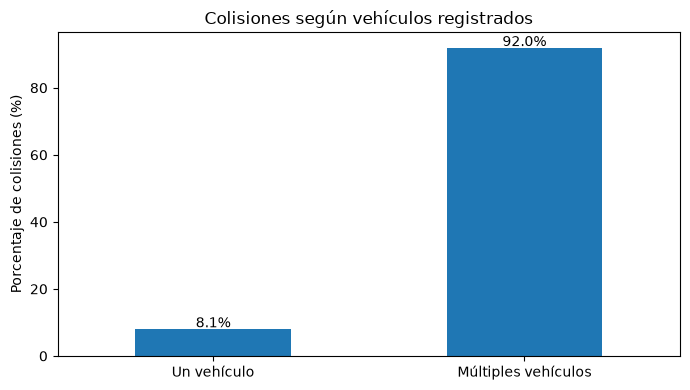

In [24]:
# Distribución por categoría
frecuencias = (
    categorias
    .groupBy("categoria")
    .agg(
        F.count("*").alias("colisiones"),
        F.round(F.avg("n_vehiculos"), 2).alias("promedio_vehiculos")
    )
    .withColumn(
        "porcentaje",
        F.round(
            100 * F.col("colisiones") / categorias.count(), 2
        )
    )
)

freq_pd = (
    frecuencias.toPandas()
    .set_index("categoria")
    .reindex(ORDEN)
)

display(freq_pd)

# Visualización
ax = freq_pd["porcentaje"].plot(
    kind="bar", figsize=(7, 4), rot=0
)

ax.set_title("Colisiones según vehículos registrados")
ax.set_ylabel("Porcentaje de colisiones (%)")
ax.set_xlabel("")

for i, valor in enumerate(freq_pd["porcentaje"]):
    ax.text(i, valor + 0.5, f"{valor:.1f}%", ha="center")

plt.tight_layout()
plt.show()

/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

categoria,Un vehículo,Múltiples vehículos
tipo_vehiculo,,
BIKE,3.02,2.62
BOX TRUCK,1.24,4.45
BUS,1.24,3.17
PICK-UP TRUCK,2.54,6.20
SEDAN,42.36,66.57
SIN DATO,6.38,14.74
STATION WAGON/SPORT UTILITY VEHICLE,33.07,54.46
TAXI,5.27,8.56
TRACTOR TRUCK DIESEL,0.71,1.66


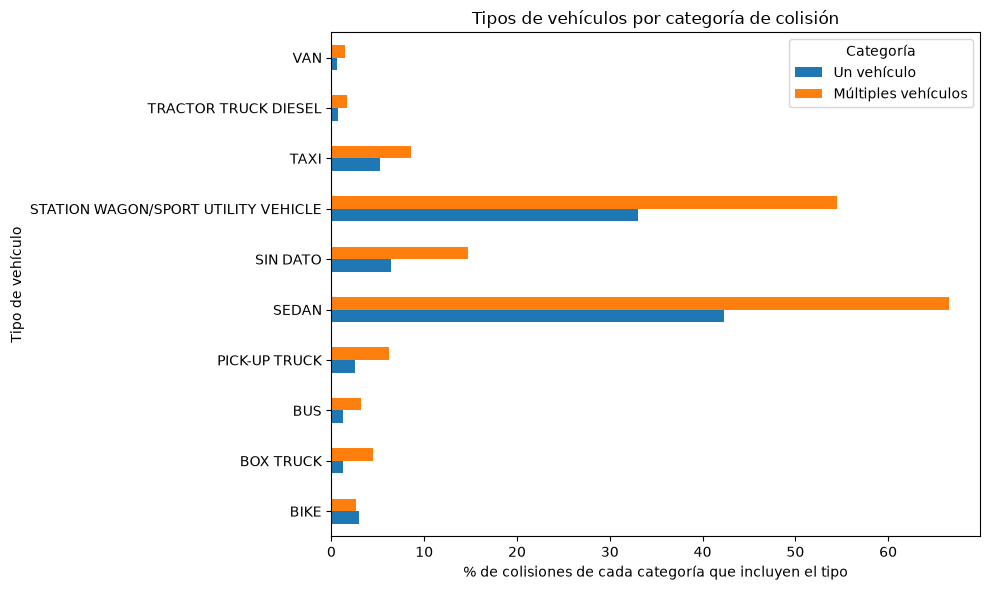

In [25]:
# Vehículos asociados a cada categoría de colisión
vehiculos_cat = (
    limpio
    .select(
        p.texto("collision_id").alias("id_colision"),
        "tipo_vehiculo"
    )
    .join(
        categorias.select("id_colision", "categoria"),
        "id_colision",
        "inner"
    )
)

# Número de colisiones en cada categoría que incluyen cada tipo
tipos_comp = (
    vehiculos_cat
    .groupBy("categoria", "tipo_vehiculo")
    .agg(
        F.countDistinct("id_colision").alias("n_colisiones")
    )
    .join(
        frecuencias.select("categoria", "colisiones"),
        "categoria"
    )
    .withColumn(
        "porcentaje",
        F.round(
            100 * F.col("n_colisiones") / F.col("colisiones"), 2
        )
    )
)

# Seleccionar los 10 tipos más frecuentes
top_tipos = (
    vehiculos_cat
    .groupBy("tipo_vehiculo")
    .agg(F.countDistinct("id_colision").alias("total"))
    .orderBy(F.desc("total"))
    .limit(10)
    .select("tipo_vehiculo")
)

tipos_pd = (
    tipos_comp
    .join(top_tipos, "tipo_vehiculo")
    .select("categoria", "tipo_vehiculo", "porcentaje")
    .toPandas()
)

matriz_tipos = (
    tipos_pd.pivot(
        index="tipo_vehiculo",
        columns="categoria",
        values="porcentaje"
    )
    .reindex(columns=ORDEN)
    .fillna(0)
)

display(matriz_tipos.round(2))

matriz_tipos.plot(kind="barh", figsize=(10, 6))
plt.title("Tipos de vehículos por categoría de colisión")
plt.xlabel("% de colisiones de cada categoría que incluyen el tipo")
plt.ylabel("Tipo de vehículo")
plt.legend(title="Categoría")
plt.tight_layout()
plt.show()

/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

categoria,Un vehículo,Múltiples vehículos
factor,,
BACKING UNSAFELY,4.10,6.07
DRIVER INATTENTION/DISTRACTION,26.32,33.55
DRIVER INEXPERIENCE,2.87,3.57
FAILURE TO YIELD RIGHT-OF-WAY,19.85,9.45
FOLLOWING TOO CLOSELY,0.56,15.78
OTHER VEHICULAR,1.74,4.25
PASSING OR LANE USAGE IMPROPER,0.87,7.76
PASSING TOO CLOSELY,1.12,6.85
TURNING IMPROPERLY,1.63,4.20


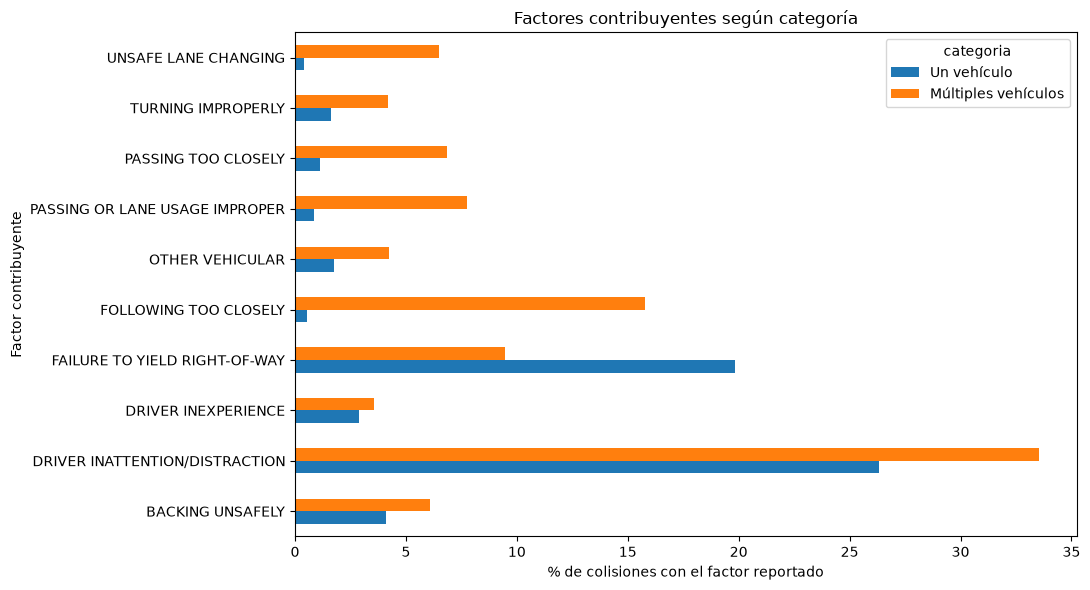

In [26]:
# Asociar los factores de cada vehículo con su colisión
factores_cat = (
    factores_detalle
    .select("unique_id", "factor")
    .join(
        limpio.select(
            "unique_id",
            p.texto("collision_id").alias("id_colision")
        ),
        "unique_id",
        "inner"
    )
    .join(
        categorias.select("id_colision", "categoria"),
        "id_colision",
        "inner"
    )
    .dropDuplicates(["id_colision", "factor"])
)

# Porcentaje de colisiones con cada factor
factores_comp = (
    factores_cat
    .groupBy("categoria", "factor")
    .agg(F.count("*").alias("n_colisiones"))
    .join(
        frecuencias.select("categoria", "colisiones"),
        "categoria"
    )
    .withColumn(
        "porcentaje",
        F.round(
            100 * F.col("n_colisiones") / F.col("colisiones"), 2
        )
    )
)

# Top 10 factores más frecuentes globalmente
top_factores = (
    factores_cat
    .groupBy("factor")
    .count()
    .orderBy(F.desc("count"))
    .limit(10)
    .select("factor")
)

factores_pd = (
    factores_comp
    .join(top_factores, "factor")
    .select("categoria", "factor", "porcentaje")
    .toPandas()
)

matriz_factores = (
    factores_pd.pivot(
        index="factor",
        columns="categoria",
        values="porcentaje"
    )
    .reindex(columns=ORDEN)
    .fillna(0)
)

display(matriz_factores.round(2))

matriz_factores.plot(kind="barh", figsize=(11, 6))
plt.title("Factores contribuyentes según categoría")
plt.xlabel("% de colisiones con el factor reportado")
plt.ylabel("Factor contribuyente")
plt.tight_layout()
plt.show()

## Cierre

Los JSON y PNG quedan guardados.

In [20]:
# Cierra sesión y limpia cache

spark.catalog.clearCache()
spark.stop()